<a href="https://colab.research.google.com/github/SabAneesah/Enhancing-Performance-with-Federated-SLMs/blob/main/proposed%20phase1/Proposed_System_Phase1_NonIID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Create a specific folder for your research project
save_path = "/content/drive/MyDrive/Research_SLM_Baseline"
if not os.path.exists(save_path):
    os.makedirs(save_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import gc
# Clear memory
gc.collect()
torch.cuda.empty_cache()

In [ ]:
import os
os.environ["RAY_memory_usage_threshold"] = "0.99" # Allow using almost all RAM

In [ ]:
# Core FL and ML libraries
!pip install flwr[simulation] torch torchvision transformers datasets peft
# For efficiency during baseline training
!pip install bitsandbytes accelerate

!pip install "protobuf<4.21.0" "ray[default]" flwr

  Using cached pydantic-1.10.26-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (155 kB)
INFO: pip is looking at multiple versions of flwr[simulation] to determine which version is compatible with other requirements. This could take a while.
  Using cached flwr-1.29.0-py3-none-any.whl.metadata (14 kB)
  Using cached cryptography-46.0.7-cp311-abi3-manylinux_2_34_x86_64.whl.metadata (5.7 kB)
  Using cached protobuf-6.33.6-cp39-abi3-manylinux2014_x86_64.whl.metadata (593 bytes)
Using cached cryptography-46.0.7-cp311-abi3-manylinux_2_34_x86_64.whl (4.5 MB)
Using cached protobuf-6.33.6-cp39-abi3-manylinux2014_x86_64.whl (323 kB)
Using cached flwr-1.29.0-py3-none-any.whl (820 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.20.3
    Uninstalling protobuf-3.20.3:
      Successfully uninstalled protobuf-3.20.3
  Attempting uninstall: cryptography
    Found existing installation: cryptography 41.0.7
    Uninstalling cryptography-41.0.7:
      

  Using cached protobuf-3.20.3-py2.py3-none-any.whl.metadata (720 bytes)
INFO: pip is looking at multiple versions of flwr to determine which version is compatible with other requirements. This could take a while.
  Using cached flwr-1.28.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.27.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.26.1-py3-none-any.whl.metadata (14 kB)
  Using cached cryptography-44.0.3-cp39-abi3-manylinux_2_34_x86_64.whl.metadata (5.7 kB)
  Using cached flwr-1.26.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.25.0-py3-none-any.whl.metadata (14 kB)
  Using cached click-8.1.8-py3-none-any.whl.metadata (2.3 kB)
  Using cached flwr-1.24.0-py3-none-any.whl.metadata (14 kB)
  Using cached flwr-1.23.0-py3-none-any.whl.metadata (14 kB)
INFO: pip is still looking at multiple versions of flwr to determine which version is compatible with other requirements. This could take a while.
  Using cached flwr-1.22.0-py3-none-any.whl.metadata (14 kB)


In [ ]:
import flwr
import torch
from google.protobuf import __version__ as pb_version

print(f"✅ Flower version: {flwr.__version__}")
print(f"✅ Protobuf version: {pb_version}")
print(f"✅ GPU Available: {torch.cuda.is_available()}")

✅ Flower version: 1.6.0
✅ Protobuf version: 3.20.3
✅ GPU Available: True


In [ ]:
import torch
import numpy as np
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"✅ Seed set to: {seed}")

set_seed(42)

✅ Seed set to: 42


In [ ]:
#base model
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model

model_id = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token
# Note: For the baseline, we use standard LoRA (PEFT) to make training feasible
lora_config = LoraConfig(r=8, lora_alpha=32, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
import torch
import flwr as fl
from collections import OrderedDict

class SLMClient(fl.client.NumPyClient):
    def __init__(self, model, train_loader, val_loader, device):
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.device = device

    def get_parameters(self, config):
        """Returns only the trainable LoRA parameters (Detached)."""
        # FIXED LINE BELOW: Added .detach()
        return [val.detach().cpu().numpy() for name, val in self.model.named_parameters() if val.requires_grad]

    def set_parameters(self, parameters):
        """Loads parameters into the trainable LoRA layers."""
        params_dict = zip([name for name, val in self.model.named_parameters() if val.requires_grad], parameters)
        state_dict = OrderedDict({k: torch.tensor(v).to(self.device) for k, v in params_dict})
        self.model.load_state_dict(state_dict, strict=False)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        self.model.train()

        # Use AdamW for better LLM stability
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=2e-4)

        print(f"  [Client] Training on {len(self.train_loader)} batches...")
        for batch in self.train_loader:
            # Move entire batch to GPU/CPU
            batch = {k: v.to(self.device) for k, v in batch.items()}

            optimizer.zero_grad()
            outputs = self.model(**batch)
            loss = outputs.loss
            loss.backward()
            optimizer.step()

        print("  [Client] Training complete.")
        return self.get_parameters(config={}), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()
        total_loss = 0.0

        with torch.no_grad():
            for batch in self.val_loader:
                batch = {k: v.to(self.device) for k, v in batch.items()}
                outputs = self.model(**batch)
                total_loss += outputs.loss.item()

        # In LLM research, we often use Perplexity (exp of loss) instead of Accuracy
        return float(total_loss / len(self.val_loader)), len(self.val_loader.dataset), {}

In [ ]:
from transformers import DataCollatorForLanguageModeling

def prepare_dataloaders(partition, tokenizer, batch_size=2):
    """
    Generalized data preparer that takes any Hugging Face partition
    and returns PyTorch Loaders.
    """
    def tokenize_function(examples):
        return tokenizer(examples["text"], truncation=True, max_length=256, padding="max_length")

    tokenized_dataset = partition.map(tokenize_function, batched=True, remove_columns=partition.column_names)

    # Data collator handles dynamic padding for LLMs
    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

    train_loader = torch.utils.data.DataLoader(
        tokenized_dataset, batch_size=batch_size, collate_fn=data_collator
    )
    return train_loader

In [ ]:
import ray
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model
from datasets import load_dataset

# This prevents 'Actor' errors and ensures the simulation can restart if it crashes
ray.init(ignore_reinit_error=True, num_cpus=2, include_dashboard=False)

# 1. SETUP (Always First)
device = "cuda" if torch.cuda.is_available() else "cpu"

# 2. MODEL LOADING
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

base_model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto" # Let transformers handle the T4 mapping
)

config = LoraConfig(
    r=8,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    task_type="CAUSAL_LM"
)
model = get_peft_model(base_model, config)

2026-04-13 15:22:33,898	INFO worker.py:2012 -- Started a local Ray instance.
/usr/local/lib/python3.12/dist-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# 1. User's Data Loading Logic
dataset = load_dataset("wikitext", "wikitext-2-raw-v1", split="train")
dataset = dataset.select(range(10000))
dataset = dataset.filter(lambda x: len(x["text"]) > 10)   # filter empty lines
partition_size = len(dataset) // 5  # Assuming 5 clients

# 2. Convert to Pandas DataFrame
df = pd.DataFrame(dataset)

# 3. Extract metadata for visualization
df['char_length'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import MiniBatchKMeans

# --- Configuration for your experiment ---
NUM_CLIENTS = 5
NUM_TOPICS = 5      # Number of distinct "themes" to discover in Wikitext
ALPHA = 0.1        # Your skew dial: 0.1 (Extreme skew), 1.0 (Moderate), 10.0 (Uniform)

print(f"Setting up Dirichlet partition with Alpha = {ALPHA}...\n")

# 1. Discover Topics (Pseudo-labels) using TF-IDF
vectorizer = TfidfVectorizer(max_features=1000, stop_words='english')
X_tfidf = vectorizer.fit_transform(df['text'])

# Fast clustering to assign a topic (0-4) to every text sequence
kmeans = MiniBatchKMeans(n_clusters=NUM_TOPICS, random_state=42, n_init="auto")
df['topic_label'] = kmeans.fit_predict(X_tfidf)
print("Finished grouping data into topics.")

# 2. Prepare the Dirichlet Distribution Logic
client_indices = {i: [] for i in range(NUM_CLIENTS)}

# For reproducibility in your research
np.random.seed(42)

for topic in range(NUM_TOPICS):
    # Get all row indices belonging to this specific topic
    topic_indices = df[df['topic_label'] == topic].index.tolist()
    np.random.shuffle(topic_indices)

    # Draw proportions for this topic across all 5 clients using the Dirichlet distribution
    proportions = np.random.dirichlet(np.repeat(ALPHA, NUM_CLIENTS))

    # Convert those probability proportions into actual row counts
    splits = (proportions * len(topic_indices)).astype(int)

    # Catch any rounding remainders and assign them to the last client
    splits[-1] = len(topic_indices) - splits[:-1].sum()

    # Distribute the actual data indices to the clients based on the splits
    start_idx = 0
    for client in range(NUM_CLIENTS):
        end_idx = start_idx + splits[client]
        client_indices[client].extend(topic_indices[start_idx:end_idx])
        start_idx = end_idx

# 3. Map the new assignments back to your DataFrame
df['dirichlet_client_id'] = -1
for client, indices in client_indices.items():
    df.loc[indices, 'dirichlet_client_id'] = int(client)

print("Dirichlet partitioning complete!")

Setting up Dirichlet partition with Alpha = 0.1...

Finished grouping data into topics.
Dirichlet partitioning complete!


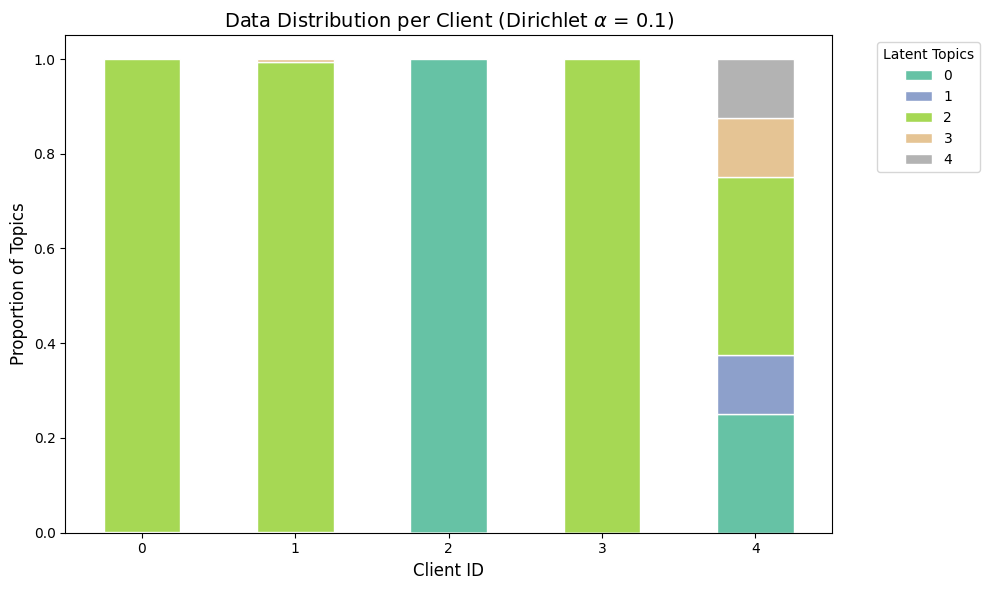

Samples per client under Dirichlet partitioning:
dirichlet_client_id
0    5299
1     649
2      21
3     502
4       8
Name: count, dtype: int64


In [ ]:
# Create a cross-tabulation of clients vs. topics
distribution_matrix = pd.crosstab(df['dirichlet_client_id'], df['topic_label'], normalize='index')

# Plot the stacked bar chart
ax = distribution_matrix.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Set2',
    edgecolor='white'
)

plt.title(f'Data Distribution per Client (Dirichlet $\\alpha$ = {ALPHA})', fontsize=14)
plt.xlabel('Client ID', fontsize=12)
plt.ylabel('Proportion of Topics', fontsize=12)

# Move legend outside the plot
plt.legend(title='Latent Topics', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Verify data quantities
print("Samples per client under Dirichlet partitioning:")
print(df['dirichlet_client_id'].value_counts().sort_index())

In [ ]:
# 3. DATA & CLIENT LOGIC (Referencing the model above)
def client_fn(cid: str):
    """
    Create a Flower client representing a single device.
    'cid' is the unique ID for the client (0, 1, 2...).
    """
    # Load model ONLY when the client is spawned
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)

    # This ensures the model is loaded into the Virtual Client's memory space, not the main script
    base_model = AutoModelForCausalLM.from_pretrained(
        model_id,
        quantization_config=bnb_config,
        device_map="auto"
    )
    model = get_peft_model(base_model, lora_config)

    # 2. Access the Dirichlet Map correctly
    # Ensure cid (str) matches the keys in your client_indices
    this_client_indices = client_indices[int(cid)]

    # 3. Create the skewed partition
    client_partition = dataset.select(this_client_indices)

    # 4. Split and Prepare
    # We do a 90/10 split on the already skewed data
    split_data = client_partition.train_test_split(test_size=0.1, seed=42)

    train_loader = prepare_dataloaders(split_data["train"], tokenizer)
    val_loader = prepare_dataloaders(split_data["test"], tokenizer)

    return SLMClient(model, train_loader, val_loader, device)

In [ ]:
# Optimization Engine (Quantization & Pruning)
import torch.nn.utils.prune as prune
import torch

def apply_optimization_engine(parameters_ndarrays, pruning_amount=0.1):
    """
    Simulates the Optimization Engine on the Central Server.
    It takes the aggregated NumPy weights and applies pruning.
    """
    # 1. Convert NumPy arrays back to PyTorch Tensors for pruning
    tensors = [torch.from_numpy(np_arr) for np_arr in parameters_ndarrays]

    optimized_tensors = []
    for t in tensors:
        # Only prune multidimensional weights (skip biases/scalars)
        if len(t.shape) > 1:
            # Simple Magnitude Pruning: zero out the smallest X% of weights
            # This satisfies the "Quantization & Pruning" block in your diagram
            flat_t = t.view(-1)
            threshold = torch.quantile(torch.abs(flat_t), pruning_amount)
            mask = torch.abs(t) > threshold
            t = t * mask
        optimized_tensors.append(t.numpy())

    return optimized_tensors

In [ ]:
from flwr.server.strategy import FedAvg
from flwr.common import ndarrays_to_parameters, parameters_to_ndarrays

class OptimizedFedAvg(FedAvg):
    def aggregate_fit(self, server_round, results, failures):
        # Call the standard FedAvg aggregation first
        aggregated_parameters, aggregated_metrics = super().aggregate_fit(server_round, results, failures)

        if aggregated_parameters is not None:
            # Convert parameters to ndarrays
            ndarrays = parameters_to_ndarrays(aggregated_parameters)

            # --- INNOVATION START: Optimization Engine ---
            print(f"Round {server_round}: Applying Optimization Engine (Pruning)...")
            optimized_ndarrays = apply_optimization_engine(ndarrays, pruning_amount=0.1)
            # --- INNOVATION END ---

            aggregated_parameters = ndarrays_to_parameters(optimized_ndarrays)

        return aggregated_parameters, aggregated_metrics

In [ ]:
# Plotting Functions
import matplotlib.pyplot as plt

def plot_federated_learning_results(history_proposed):
    """
    Visualizes the training loss over federated rounds.
    """
    # Extracting loss from history
    rounds, losses = zip(*history_proposed.losses_distributed)

    plt.figure(figsize=(10, 6))
    plt.plot(rounds, losses, marker='o', linestyle='-', color='b', label='Baseline (FedAvg)')
    plt.title('Federated Learning Training Loss (TinyLlama Baseline)')
    plt.xlabel('Federated Round')
    plt.ylabel('Distributed Loss')
    plt.grid(True)
    plt.legend()

    # Save the plot for your thesis/report
    plt.savefig("federated_learning_loss.png")
    plt.show()

INFO flwr 2026-04-13 15:23:04,795 | app.py:178 | Starting Flower simulation, config: ServerConfig(num_rounds=5, round_timeout=None)
INFO:flwr:Starting Flower simulation, config: ServerConfig(num_rounds=5, round_timeout=None)
2026-04-13 15:23:15,085	INFO worker.py:2012 -- Started a local Ray instance.
INFO flwr 2026-04-13 15:23:27,369 | app.py:213 | Flower VCE: Ray initialized with resources: {'accelerator_type:T4': 1.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'node:__internal_head__': 1.0, 'CPU': 2.0, 'object_store_memory': 3933130752.0, 'memory': 9177305088.0}
INFO:flwr:Flower VCE: Ray initialized with resources: {'accelerator_type:T4': 1.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'node:__internal_head__': 1.0, 'CPU': 2.0, 'object_store_memory': 3933130752.0, 'memory': 9177305088.0}
INFO flwr 2026-04-13 15:23:27,377 | app.py:219 | Optimize your simulation with Flower VCE: https://flower.dev/docs/framework/how-to-run-simulations.html
INFO:flwr:Optimize your simulation with Flower VCE: https:

(DefaultActor pid=29383)   [Client] Training on 292 batches...
(DefaultActor pid=29383)   [Client] Training complete.


Loading weights: 100%|██████████| 201/201 [00:01<00:00, 194.22it/s, Materializing param=model.norm.weight]


(DefaultActor pid=29383)   [Client] Training on 2385 batches...
(DefaultActor pid=29383)   [Client] Training complete.


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 217.46it/s, Materializing param=model.norm.weight]


(DefaultActor pid=29383)   [Client] Training on 4 batches...
(DefaultActor pid=29383)   [Client] Training complete.


... (52 outputs left out)

DEBUG flwr 2026-04-13 16:55:02,098 | server.py:236 | fit_round 5 received 5 results and 0 failures
DEBUG:flwr:fit_round 5 received 5 results and 0 failures


(DefaultActor pid=29383)   [Client] Training complete.
Round 5: Applying Optimization Engine (Pruning)...


DEBUG flwr 2026-04-13 16:55:02,275 | server.py:173 | evaluate_round 5: strategy sampled 5 clients (out of 5)
DEBUG:flwr:evaluate_round 5: strategy sampled 5 clients (out of 5)
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 263.33it/s, Materializing param=model.norm.weight]
DEBUG flwr 2026-04-13 16:56:06,959 | server.py:187 | evaluate_round 5 received 5 results and 0 failures
DEBUG:flwr:evaluate_round 5 received 5 results and 0 failures
INFO flwr 2026-04-13 16:56:06,960 | server.py:153 | FL finished in 5519.099544168001
INFO:flwr:FL finished in 5519.099544168001
INFO flwr 2026-04-13 16:56:06,964 | app.py:226 | app_fit: losses_distributed [(1, 2.281666500122718), (2, 2.2604840785926537), (3, 2.2698615773050763), (4, 2.285290637702867), (5, 2.3078041029713883)]
INFO:flwr:app_fit: losses_distributed [(1, 2.281666500122718), (2, 2.2604840785926537), (3, 2.2698615773050763), (4, 2.285290637702867), (5, 2.3078041029713883)]
INFO flwr 2026-04-13 16:56:06,967 | app.py:227 | app_fit: me

✅ Final Global Model Weights Saved!
✅ Phase 1 Baseline Results Saved!


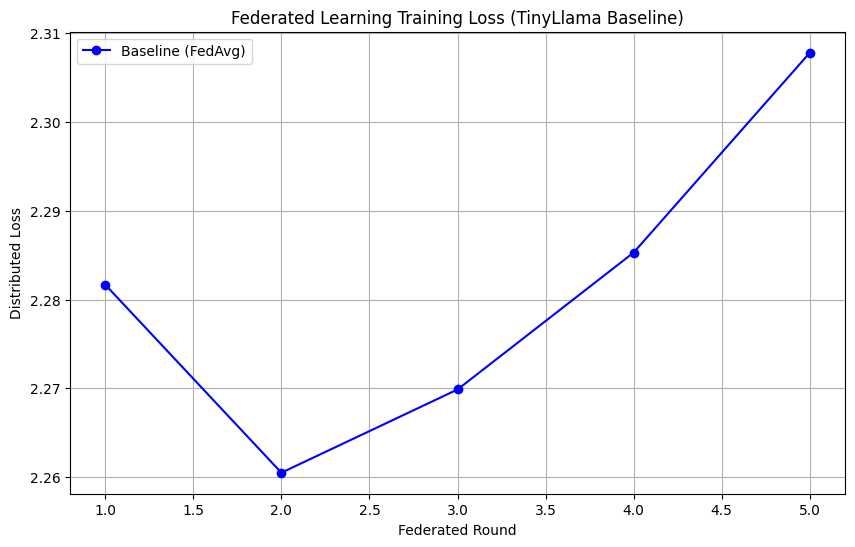

In [ ]:
import pandas as pd
import numpy as np
import flwr as fl

# 1. Define the Strategy
strategy = OptimizedFedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=5,
    min_available_clients=5,
)

# 2. Start the Simulation (This runs all 5 rounds automatically)
history_proposed = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=5),
    strategy=strategy,
    client_resources={"num_gpus": 0.9, "num_cpus": 2} # Good for T4 GPU
)
# SAVE PTH
torch.save(model.state_dict(), 'tinyllama_fed_baseline.pth')
print("✅ Final Global Model Weights Saved!")

# 3. Extract metrics from the 'history_proposed' object
# Flower stores results in history_proposed.losses_distributed
results_log = []

for r, loss in history_proposed.losses_distributed:
    stats = {
        "round": r,
        "loss": loss,
        "perplexity": np.exp(loss),
        "comm_size_mb": 4400, # Approximate size for the baseline
        "protocol": "FP32 (Baseline)"
    }
    results_log.append(stats)

# 4. Save to CSV
df = pd.DataFrame(results_log)
df.to_csv("phase1_baseline_results.csv", index=False)
print("✅ Phase 1 Baseline Results Saved!")
plot_federated_learning_results(history_proposed)

In [ ]:
def save_lora_adapters(model, folder_name="baseline_round_3"):
    """
    Saves the LoRA adapter weights and configuration to Google Drive.
    """
    full_path = os.path.join(save_path, folder_name)
    # Save the adapter weights and the config file
    model.save_pretrained(full_path)

    # Also save the tokenizer so you can run inference easily later
    tokenizer.save_pretrained(full_path)

    print(f"✅ LoRA adapters successfully saved to: {full_path}")

# Execute saving after the simulation ends
save_lora_adapters(model)

✅ LoRA adapters successfully saved to: /content/drive/MyDrive/Research_SLM_Baseline/baseline_round_3


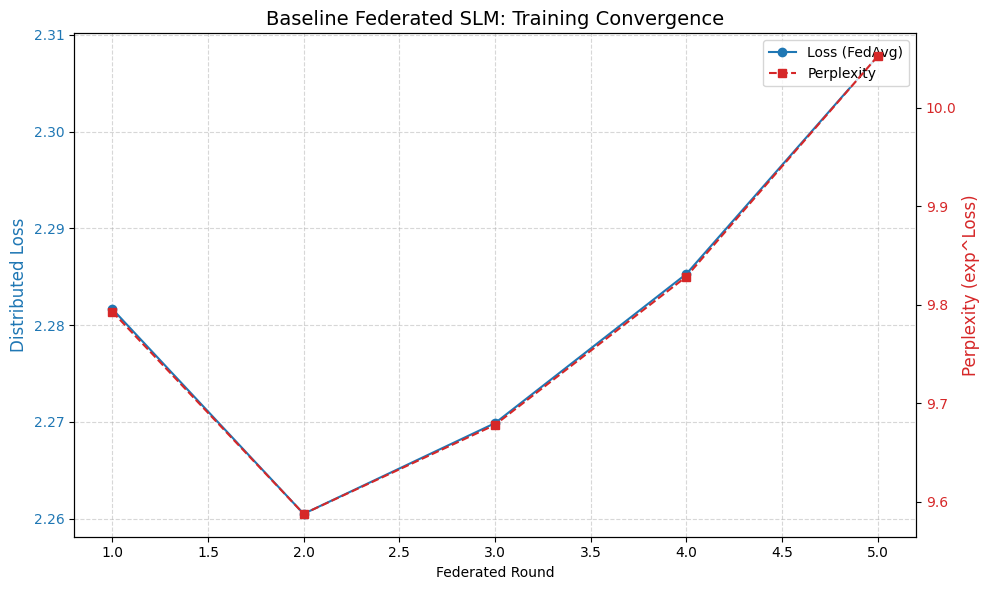

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_baseline_metrics(history_proposed):
    """
    Plots both Distributed Loss and Perplexity on a dual-axis graph.
    """
    # Extract data from Flower history
    rounds, losses = zip(*history_proposed.losses_distributed)

    # Calculate Perplexity: e^Loss
    perplexities = [np.exp(l) for l in losses]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # --- Axis 1: Distributed Loss ---
    color_loss = 'tab:blue'
    ax1.set_xlabel('Federated Round')
    ax1.set_ylabel('Distributed Loss', color=color_loss, fontsize=12)
    ax1.plot(rounds, losses, marker='o', linestyle='-', color=color_loss, label='Loss (FedAvg)')
    ax1.tick_params(axis='y', labelcolor=color_loss)
    ax1.grid(True, which='both', linestyle='--', alpha=0.5)

    # --- Axis 2: Perplexity ---
    ax2 = ax1.twinx()  # Create a second y-axis that shares the same x-axis
    color_ppl = 'tab:red'
    ax2.set_ylabel('Perplexity (exp^Loss)', color=color_ppl, fontsize=12)
    ax2.plot(rounds, perplexities, marker='s', linestyle='--', color=color_ppl, label='Perplexity')
    ax2.tick_params(axis='y', labelcolor=color_ppl)

    # Final touches
    plt.title('Baseline Federated SLM: Training Convergence', fontsize=14)
    fig.tight_layout()

    # Add a combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.savefig("baseline_metrics_dual_axis.png")
    plt.show()

# Run the updated visualization
plot_baseline_metrics(history_proposed)

In [ ]:
for r, loss in history_proposed.losses_distributed:
    stats = {
        "round": r,
        "loss": loss,
        "perplexity": np.exp(loss),
        "data_distribution": "Dirichlet (Alpha=0.5)", # Log the skewness
        "partitioning": "K-Means Topic-Based"
    }
    results_log.append(stats)